### Practical Implementation (PyTorch)
Using PyTorch, implement a simple custom RNN cell or module that processes a sequence of at least 5
time steps (T ≥ 5). Compute a scalar loss, call .backward(), and print the gradient tensor (.grad) for
each model parameter. Explain what these parameter gradients physically represent.

PyTorch calculates the gradients for every trainable parameter.

W_xh.grad: Shows how much the loss changes when the input-to-hidden weights change.
W_hh.grad: Shows how much the loss changes when the recurrent/hidden-to-hidden weights change. It receives contributions from multiple time steps.
b.grad: Shows how much the loss changes when the bias changes.

### RNN Equation:
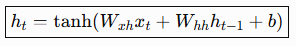

* Forward pass: The RNN reads 5 inputs one by one and updates its memory (hidden state).
* Loss: We add the values of the final hidden state to get one scalar loss.
* Backward pass: .backward() goes backward through all 5 time steps and calculates how each weight and bias affected the loss.
* Gradients: The .grad tensors tell us how the parameters should change to reduce the loss during learning.

In [7]:
import torch    # Imports the main PyTorch library
import torch.nn as nn  # Imports PyTorch's neural network module use to create our own RNN

# For reproducible results
torch.manual_seed(42)  
# generates random numbers for: input data, RNN weights
# we get the same random values each time


# Custom RNN Cell
class SimpleRNN(nn.Module):   # creates a class called SimpleRNN inherits from nn.Module
    def __init__(self, input_size, hidden_size):   # Constructor, It receives two values
        super().__init__()  # Initialize the Parent Class

        # Learnable parameters
        self.W_xh = nn.Parameter(torch.randn(hidden_size, input_size))  # Creates the weight matrix from the input to the hidden layer
        self.W_hh = nn.Parameter(torch.randn(hidden_size, hidden_size))  # Hidden-to-Hidden Weights
        self.b = nn.Parameter(torch.zeros(hidden_size))   # Creates the bias vector

    def forward(self, x):  # forward() function defines how the RNN processes the input
        # x shape: (T, input_size)
        T = x.size(0)   # Get Number of Time Steps

        # Initial hidden state
        h = torch.zeros(self.W_hh.size(0))   # Initial Hidden State

        # Process each time step
        for t in range(T):  # Processes the sequence one time step at a time.
            h = torch.tanh(self.W_xh @ x[t] +  self.W_hh @ h + self.b) # RNN Equation, @ symbol is used for matrix multiplication

        return h   # Returns the final hidden state h5


# Create input sequence
T = 5   # 5 time steps
input_size = 3   # Input size 
hidden_size = 4  # Hidden size

x = torch.randn(T, input_size)  # Creates random input data/sequence

# Create model
model = SimpleRNN(input_size, hidden_size)   # Create the RNN Model

# Forward Pass
h5 = model(x)   # This sends the complete sequence through the RNN

# Displays the final hidden state
print("Final hidden state h5:")
print(h5)


# Compute scalar loss
loss = h5.sum()  # Calculate Scalar Loss

print("\nLoss:")
print(loss.item())  # Converts the single-value tensor into a normal Python number

# Backpropagation
loss.backward()   # to calculate gradients

# Print gradients
print("\nParameter Gradients:")

for name, parameter in model.named_parameters():  # named_parameters() returns every trainable parameter and its name
    print(f"\n{name}.grad:")   # Prints the name of the parameter
    print(parameter.grad)  # prints the gradient calculated by loss.backward()

Final hidden state h5:
tensor([-1.0000, -0.9294,  0.7515,  0.9506], grad_fn=<TanhBackward0>)

Loss:
-0.2271537184715271

Parameter Gradients:

W_xh.grad:
tensor([[ 0.2428, -0.0088,  0.0574],
        [ 0.2369, -0.0992, -0.0286],
        [ 0.3745, -1.0334, -0.6039],
        [-0.0653, -0.1425, -0.0717]])

W_hh.grad:
tensor([[-0.1473,  0.1006, -0.0966,  0.0149],
        [ 0.1149,  0.0955, -0.1113, -0.0037],
        [ 0.5220,  0.4489, -0.3801,  0.0174],
        [ 0.2987, -0.0863,  0.1033,  0.0255]])

b.grad:
tensor([-0.0026,  0.3546,  0.1634,  0.2308])
